# Research-informed LSTM optimization on IMDB

This notebook executes a **registered 16-configuration validation study**, freezes its selection, and evaluates **only the selected model** on the official test partition. The original benchmark model classes, training protocol, configuration, notebook, checkpoints, and results remain unchanged.

Full mode uses 20,000 training / 5,000 validation / 25,000 final test reviews, seed 42, with randomly initialized trainable embeddings. No pretrained embeddings, unlabeled data, or test-based hyperparameter selection are used.

**Local:** run from the project folder with the existing environment. **Colab:** choose a GPU runtime, open this notebook, and upload `imdb-optimization-project.zip` when prompted. See `README_OPTIMIZATION.md`.

## 1. Setup and research context

[Hameed & Garcia-Zapirain (2020)](https://doi.org/10.1109/ACCESS.2020.2988550) motivates a single BiLSTM layer with mean/max pooling, regularization and evaluation of 400-token inputs. Its GloVe and cross-validation protocol differ from ours.

[Sachan et al.](https://arxiv.org/abs/2009.04007) motivates max pooling, word/embedding dropout, vocabulary ablations and LR decay. Its pretrained embeddings and semi-supervised objectives are excluded.

The [Keras example](https://keras.io/examples/nlp/bidirectional_lstm_imdb/) illustrates bidirectional recurrence. We retain a separate validation set instead of following its use of the official test partition for validation.

These are adaptations and local hypotheses, not a reproduction of published scores.

In [1]:
from pathlib import Path
import importlib.util
import json
import os
import subprocess
import sys
import zipfile

IN_COLAB = "google.colab" in sys.modules
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "configs" / "lstm_ablation.yaml").exists():
    if not IN_COLAB:
        raise FileNotFoundError("Start this notebook in the project folder.")
    from google.colab import files
    uploaded = files.upload()
    archives = [name for name in uploaded if name.endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Upload one imdb-optimization-project.zip archive.")
    PROJECT_ROOT = Path("/content/imdb-optimization-project")
    PROJECT_ROOT.mkdir(exist_ok=True)
    with zipfile.ZipFile(archives[0]) as archive:
        for item in archive.infolist():
            if not (PROJECT_ROOT / item.filename).resolve().is_relative_to(PROJECT_ROOT.resolve()):
                raise ValueError("Unsafe archive path")
        archive.extractall(PROJECT_ROOT)
    os.chdir(PROJECT_ROOT)
if importlib.util.find_spec("imdb_sentiment") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-e", ".[notebook,test]"], check=True)
os.environ.setdefault("HF_HOME", str(PROJECT_ROOT / ".cache" / "huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))

import pandas as pd
import torch
from IPython.display import display, Image, Markdown
from imdb_sentiment.optimization_config import load_study_config, candidate_config
from imdb_sentiment.lstm_ablation import run_study, evaluate_selected, report_study, read_json
from imdb_sentiment.reproducibility import environment, get_device
display(environment(get_device()))

C:\Users\letie\Documents\Journals\NLP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.11.15',
 'platform': 'Windows-10-10.0.26200-SP0',
 'device': 'cuda',
 'gpu': 'NVIDIA GeForce RTX 3060',
 'versions': {'torch': '2.11.0+cu128',
  'datasets': '5.1.0',
  'scikit-learn': '1.9.1',
  'numpy': '2.4.6',
  'pandas': '3.1.0',
  'matplotlib': '3.11.2',
  'PyYAML': '6.0.3',
  'joblib': '1.6.0'},
 'determinism_note': 'Seeds and deterministic cuDNN settings reduce variation; GPU results are not guaranteed bitwise identical across hardware or versions.'}

## 2. Register the study

The anchor uses vocabulary 30,000; head-only length 400; one bidirectional LSTM with embedding size 128 and hidden size 128 per direction; masked mean-max pooling; embedding/classifier dropout 0.2/0.4; Adam learning rate 0.0005; weight decay 0.0001; clipping 1; at most 15 epochs; patience four; minimum loss improvement 0.0001.

Each non-control experiment changes only its listed setting relative to the anchor. The final short-budget experiment changes both epochs and patience. Word dropout replaces ordinary tokens with UNK during training, preserving sequence lengths and PAD. Mean/max pooling masks all padded positions.

Set `MODE = "smoke"` for a small execution check. Smoke changes sequence limits/dimensions and cannot establish which settings improve real IMDB performance.

In [2]:
MODE = "full"
config = load_study_config(PROJECT_ROOT / "configs" / "lstm_ablation.yaml")
display(pd.DataFrame([{"experiment_id": item["id"], "description": item["description"], "overrides": json.dumps(item["overrides"])} for item in config["experiments"]]))
print(json.dumps({key: value for key, value in config.items() if key != "experiments"}, indent=2))
print("MODE:", MODE.upper())
if not torch.cuda.is_available():
    print("CPU fallback: the 16 full experiments may take substantially longer.")

,experiment_id,description,overrides
0,01_original_control,Fresh unchanged original LSTM and training pro...,{}
1,02_anchor,Suggested starting configuration,{}
2,03_vocab_20000,Vocabulary 20000,"{""data"": {""max_vocab_size"": 20000}}"
3,04_length_300,Sequence length 300,"{""data"": {""max_seq_len"": 300}}"
4,05_length_500,Sequence length 500,"{""data"": {""max_seq_len"": 500}}"
5,06_head_tail,Head-tail truncation,"{""data"": {""truncation"": ""head_tail""}}"
6,07_unidirectional,Unidirectional recurrence,"{""neural"": {""bidirectional"": false}}"
7,08_final_pooling,Final-state pooling,"{""neural"": {""pooling"": ""final""}}"
8,09_max_pooling,Masked max pooling,"{""neural"": {""pooling"": ""max""}}"
9,10_no_embedding_dropout,Embedding dropout disabled,"{""neural"": {""embedding_dropout"": 0.0}}"


{
  "seed": 42,
  "reference_run": "outputs/full-20261027T170840-4f2309dd",
  "output_dir": "outputs/lstm_optimization",
  "device": "auto",
  "data": {
    "dataset_name": "stanfordnlp/imdb",
    "validation_fraction": 0.2,
    "lowercase": true,
    "max_vocab_size": 30000,
    "max_seq_len": 400,
    "truncation": "head",
    "batch_size": 64,
    "num_workers": 0
  },
  "neural": {
    "embedding_dim": 128,
    "hidden_dim": 128,
    "num_layers": 1,
    "bidirectional": true,
    "pooling": "mean_max",
    "embedding_dropout": 0.2,
    "classifier_dropout": 0.4,
    "word_dropout": 0.0,
    "optimizer": "adam",
    "learning_rate": 0.0005,
    "weight_decay": 0.0001,
    "grad_clip": 1.0,
    "epochs": 15,
    "early_stopping_patience": 4,
    "early_stopping_min_delta": 0.0001,
    "selection_metric": "val_loss",
    "scheduler": "none",
    "scheduler_gamma": 0.95
  }
}
MODE: FULL


## 3. Train and select using training/validation only

This stage requests only the official training partition, verifies dataset fingerprints and the exact original training/validation review IDs, and builds training-only vocabularies. All candidates use the same seed and shuffle protocol.

The original control runs the unchanged model and trainer in a new directory. Other configurations use the opt-in optimized model. Every checkpoint is selected and restored by **validation loss**. Configuration selection then ranks these restored checkpoints by **validation accuracy**, then positive-class F1, then lower loss, then experiment ID.

The winner is frozen only after all 16 candidates finish. A selection file binds its configuration, checkpoint and vocabulary hashes to the study's split. No test dataset is loaded by this stage. Training progress and histories are persisted per experiment.

In [3]:
STUDY_DIR = run_study(config, mode=MODE)
print("Study directory:", STUDY_DIR.resolve())
ablation = pd.read_csv(STUDY_DIR / "ablation_comparison.csv")
display(ablation)
selection = read_json(STUDY_DIR / "selection.json")
display(selection)
assert read_json(STUDY_DIR / "study_metadata.json")["status"] == "selected"
assert not (STUDY_DIR / "final").exists()

Using the latest cached version of the dataset since stanfordnlp/imdb couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'plain_text' at C:\Users\letie\Documents\Journals\NLP\.cache\huggingface\datasets\stanfordnlp___imdb\plain_text\0.0.0\e6281661ce1c48d982bc483cf8a173c1bbeb5d31 (last modified on Wed Oct 28 00:04:34 2026).


Study: C:\Users\letie\Documents\Journals\NLP\outputs\lstm_optimization\full-20261027T181317-42224b37 | mode=full | train=20000 val=5000 | cuda



--- 01_original_control: Fresh unchanged original LSTM and training protocol ---


epoch 1: train_loss=0.6302, val_loss=0.5917, val_f1=0.7299


...

epoch 8/8: lr=0.0005, train_loss=0.2975, val_loss=0.3633, val_accuracy=0.8552, val_f1=0.8596


Frozen validation winner: 12_word_dropout; test data has not been loaded.


Study directory: C:\Users\letie\Documents\Journals\NLP\outputs\lstm_optimization\full-20261027T181317-42224b37


,experiment_id,status,description,val_accuracy,val_f1,val_loss,training_seconds,best_epoch,epochs_trained,parameter_count,config_hash,checkpoint_sha256,delta_accuracy_pp,delta_f1,delta_loss
0,01_original_control,complete,Fresh unchanged original LSTM and training pro...,0.8452,0.851382,0.395963,53.711822,5,7,2692225,1b3d575991d3e56d9fe107df40e4b6fbf7f6bc4e845b17...,7cd1efc0075c5315c4dbbf6d838fda706ab87be5956e8a...,-3.42,-0.024416,0.116468
1,02_anchor,complete,Suggested starting configuration,0.8794,0.875798,0.279495,329.172206,15,15,4104705,892a0c1fdd2d1ccce559097503d54647fde0007dc40397...,e783d5d6ed746a1d18b58de91ccf421b23ddc0c5987e89...,0.00,0.000000,0.000000
2,03_vocab_20000,complete,Vocabulary 20000,0.8768,0.882038,0.291534,327.520837,14,15,2824705,ca6d31a7b791e5d38e87823ca9b1ceec78791dce400c75...,24e0d91de5e92498f16dc23211d63d20f0ab242ce31153...,-0.26,0.006239,0.012039
3,04_length_300,complete,Sequence length 300,0.8714,0.868749,0.303521,253.619604,12,15,4104705,6d377ece584ce5a1a670582d4eab47e1e8a8b0a1f1216a...,ada4050bc928050139c33c5ed682c7fac2e983bd18921e...,-0.80,-0.007049,0.024026
4,05_length_500,complete,Sequence length 500,0.8840,0.885012,0.281916,382.568594,15,15,4104705,b672c4f6500c96bb2d8a9750bd8885e72f4426a0c1e52e...,af13870b901b37b1620fd21b23a7359aa2e7b3e55d511d...,0.46,0.009214,0.002421
5,06_head_tail,complete,Head-tail truncation,0.8804,0.881443,0.279998,323.330971,15,15,4104705,63f5481f7cac03c84305d17208a0fe33fc69b71a10ae13...,cc0308fb1fb96435a94898e23d3b8cb23ba939766baa85...,0.10,0.005645,0.000503
6,07_unidirectional,complete,Unidirectional recurrence,0.8666,0.867947,0.321120,167.934704,8,12,3972353,20eb4810be0900dfab1f9b64ba8a4a4cd78c7de9b936da...,2740c74a89bfe415ee83a0c8e3c3e89a8c08e90e59d32e...,-1.28,-0.007851,0.041625
7,08_final_pooling,complete,Final-state pooling,0.8658,0.859594,0.321883,213.575170,14,15,4104449,79b77ae4e385eade45415185d5cafc6becb92219c47aca...,5d82a70268fd25557b4cf605fee881e8ff022bc161edc1...,-1.36,-0.016204,0.042388
8,09_max_pooling,complete,Masked max pooling,0.8842,0.883852,0.279085,316.537759,14,15,4104449,cd0a8e01332bb24badaea9a5b5953f60817b186d3f9eef...,aac5920e5f22ffb3c2470a13c5686a90310adecdb27e99...,0.48,0.008053,-0.000410
9,10_no_embedding_dropout,complete,Embedding dropout disabled,0.8784,0.876623,0.313361,323.527027,14,15,4104705,fab99a0069d78209506f1229caacc323d33bb43b58fcbb...,351128b97533093e71dc8e605503507d8f2b41c698b6b2...,-0.10,0.000825,0.033866


{'experiment_id': '12_word_dropout',
 'validation': {'experiment_id': '12_word_dropout',
  'status': 'complete',
  'description': 'Word dropout 0.1',
  'val_accuracy': 0.8862,
  'val_f1': 0.8890189194460698,
  'val_loss': 0.282515154671669,
  'training_seconds': 324.81518259999575,
  'best_epoch': 15,
  'epochs_trained': 15,
  'parameter_count': 4104705,
  'config_hash': '3ac3cf73bedb6b77c1a1e3c4d3bb0dfe63d4b44218456cdae363972a636a9f9b',
  'checkpoint_sha256': 'a2202774fcaebdaef68819a23a44c622418b5e76b97641c3a9b327888bb803df'},
 'config': {'seed': 42,
  'output_dir': 'outputs/lstm_optimization',
  'device': 'auto',
  'data': {'dataset_name': 'stanfordnlp/imdb',
   'validation_fraction': 0.2,
   'lowercase': True,
   'max_vocab_size': 30000,
   'max_seq_len': 400,
   'truncation': 'head',
   'batch_size': 64,
   'num_workers': 0},
  'neural': {'embedding_dim': 128,
   'hidden_dim': 128,
   'num_layers': 1,
   'bidirectional': True,
   'pooling': 'mean_max',
   'embedding_dropout': 0.2,


## 4. Inspect validation evidence and learning curves

Positive accuracy differences mean improvement relative to the anchor for this seed. Negative differences mean regression. The original control versus anchor is a bundle comparison. Small differences are not statistical significance.

A longer review limit retains more context but costs time; head-tail truncation preserves endings while introducing an artificial junction. Bidirectionality changes parameter count. These tradeoffs must be evaluated from the recorded measurements.

,experiment_id,val_accuracy,val_f1,val_loss,delta_accuracy_pp,training_seconds,best_epoch
11,12_word_dropout,0.8862,0.889019,0.282515,0.68,324.815183,15
8,09_max_pooling,0.8842,0.883852,0.279085,0.48,316.537759,14
4,05_length_500,0.8840,0.885012,0.281916,0.46,382.568594,15
5,06_head_tail,0.8804,0.881443,0.279998,0.10,323.330971,15
14,15_learning_rate_001,0.8802,0.882249,0.281996,0.08,213.607760,6
1,02_anchor,0.8794,0.875798,0.279495,0.00,329.172206,15
10,11_classifier_dropout_03,0.8792,0.879297,0.290229,-0.02,323.377702,14
9,10_no_embedding_dropout,0.8784,0.876623,0.313361,-0.10,323.527027,14
2,03_vocab_20000,0.8768,0.882038,0.291534,-0.26,327.520837,14
3,04_length_300,0.8714,0.868749,0.303521,-0.80,253.619604,12


01_original_control


,epoch,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_macro_f1,learning_rate
0,1,0.630170,0.591683,0.6902,0.646986,0.8372,0.729904,0.683358,0.001
1,2,0.503188,0.480022,0.7826,0.785917,0.7768,0.781332,0.782593,0.001
2,3,0.392386,0.451641,0.7988,0.853025,0.7220,0.782062,0.797606,0.001
3,4,0.311813,0.419191,0.8174,0.876960,0.7384,0.801737,0.816253,0.001
4,5,0.246791,0.395963,0.8452,0.818685,0.8868,0.851382,0.844932,0.001
5,6,0.184350,0.438831,0.8376,0.797602,0.9048,0.847826,0.836863,0.001
6,7,0.138925,0.428878,0.8554,0.845049,0.8704,0.857537,0.855367,0.001


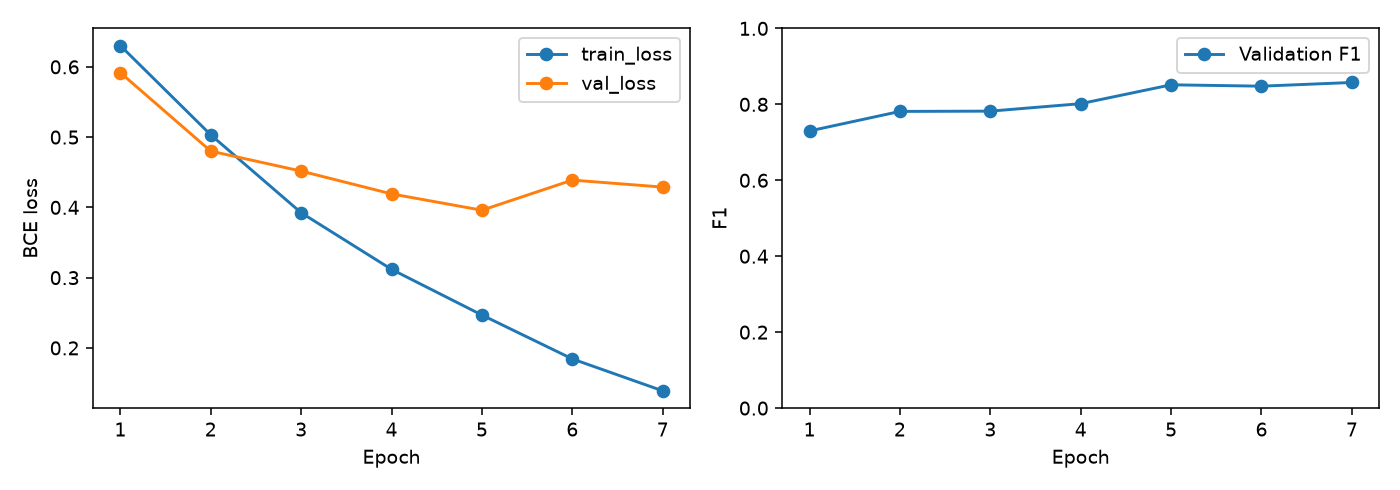

02_anchor


,epoch,learning_rate,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_macro_f1
0,1,0.0005,0.603259,0.598892,0.7124,0.747668,0.6412,0.690353,0.710935
1,2,0.0005,0.465692,0.433824,0.8140,0.817044,0.8092,0.813103,0.813996
2,3,0.0005,0.403117,0.393336,0.8268,0.874084,0.7636,0.815115,0.826105
3,4,0.0005,0.367721,0.393099,0.8390,0.848622,0.8252,0.836747,0.838969
4,5,0.0005,0.342873,0.367822,0.8406,0.820233,0.8724,0.845513,0.840439
5,6,0.0005,0.325994,0.348741,0.8450,0.820513,0.8832,0.850703,0.844773
6,7,0.0005,0.311696,0.332550,0.8578,0.859093,0.8560,0.857544,0.857800
7,8,0.0005,0.297499,0.363253,0.8552,0.834086,0.8868,0.859636,0.855055
8,9,0.0005,0.279434,0.391579,0.8434,0.788766,0.9380,0.856934,0.841986
9,10,0.0005,0.268204,0.309973,0.8672,0.870161,0.8632,0.866667,0.867198


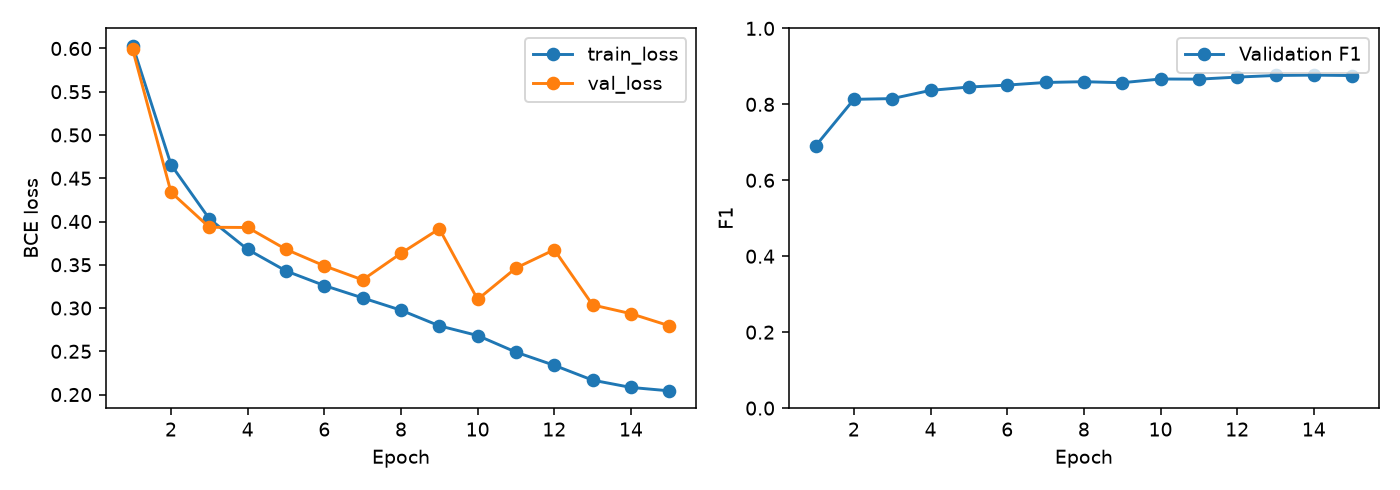

12_word_dropout


,epoch,learning_rate,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_macro_f1
0,1,0.0005,0.629480,0.498637,0.7602,0.772290,0.7380,0.754756,0.760082
1,2,0.0005,0.494969,0.432035,0.8070,0.792604,0.8316,0.811634,0.806883
2,3,0.0005,0.437348,0.388594,0.8300,0.836460,0.8204,0.828352,0.829984
3,4,0.0005,0.395266,0.380204,0.8382,0.856902,0.8120,0.833847,0.838089
4,5,0.0005,0.365323,0.382568,0.8376,0.799503,0.9012,0.847311,0.836940
5,6,0.0005,0.349264,0.344508,0.8470,0.810154,0.9064,0.855579,0.846458
6,7,0.0005,0.329371,0.323806,0.8638,0.865408,0.8616,0.863500,0.863799
7,8,0.0005,0.318772,0.323715,0.8676,0.851031,0.8912,0.870653,0.867526
8,9,0.0005,0.292925,0.322247,0.8664,0.836517,0.9108,0.872080,0.866136
9,10,0.0005,0.284460,0.310357,0.8722,0.901251,0.8360,0.867400,0.872032


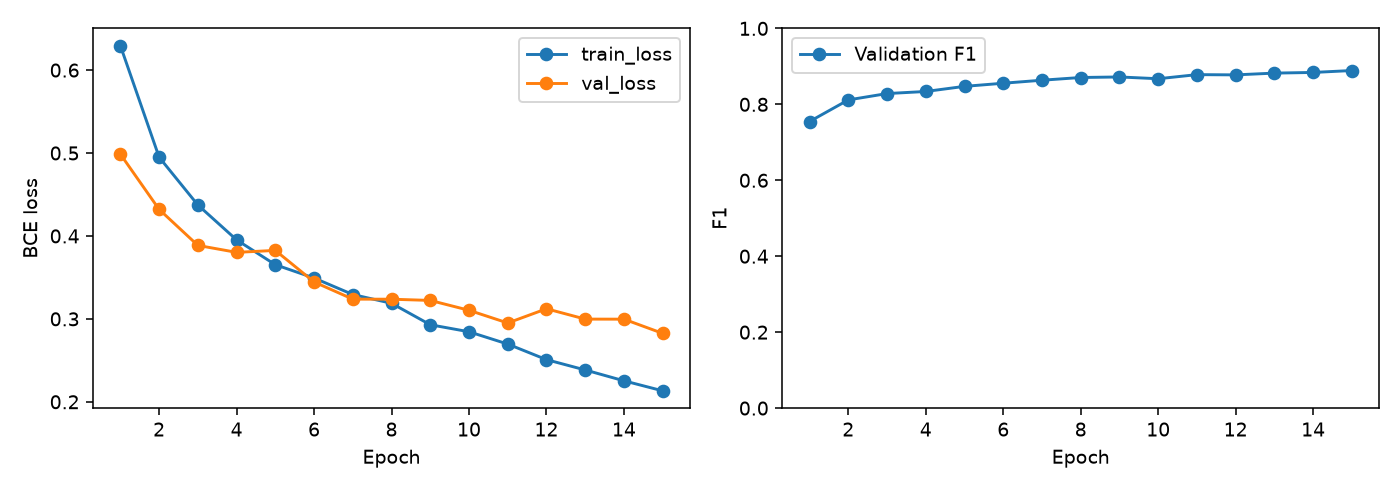

In [4]:
display(ablation[["experiment_id", "val_accuracy", "val_f1", "val_loss", "delta_accuracy_pp", "training_seconds", "best_epoch"]].sort_values("val_accuracy", ascending=False))
for experiment_id in [config["experiments"][0]["id"], config["experiments"][1]["id"], selection["experiment_id"]]:
    print(experiment_id)
    display(pd.read_csv(STUDY_DIR / experiment_id / "history.csv"))
    display(Image(filename=str(STUDY_DIR / experiment_id / "learning_curves.png")))

## 5. Final evaluation of the frozen selection

Only now is the official test split loaded. The selected checkpoint, configuration, vocabulary and split hashes must match the frozen record. Evaluation uses all 25,000 test reviews in full mode and logit ≥ 0 as the fixed decision rule.

No refitting on validation data or threshold tuning occurs. The historical benchmark results are read only for the final report; they do not select candidates. Only the selected model receives a new test evaluation.

Using the latest cached version of the dataset since stanfordnlp/imdb couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'plain_text' at C:\Users\letie\Documents\Journals\NLP\.cache\huggingface\datasets\stanfordnlp___imdb\plain_text\0.0.0\e6281661ce1c48d982bc483cf8a173c1bbeb5d31 (last modified on Wed Oct 28 00:04:34 2026).


Selected model test accuracy=0.8853, F1=0.8886; C:\Users\letie\Documents\Journals\NLP\outputs\lstm_optimization\full-20261027T181317-42224b37\final


{'accuracy': 0.88528,
 'precision': 0.8634168427407184,
 'recall': 0.91536,
 'f1': 0.8886300093196645,
 'macro_f1': 0.8851761066063846,
 'confusion_matrix': [[10690, 1810], [1058, 11442]],
 'loss': 0.28348474555492403}

,model,status,accuracy,precision,recall,f1,macro_f1,training_seconds,parameter_count,loss
0,logreg,historical benchmark,0.90232,0.902320,0.90232,0.902320,0.902320,3.486604,100001,NaN
1,svm,historical benchmark,0.90088,0.902878,0.89840,0.900634,0.900879,3.535550,100001,NaN
2,rnn,historical benchmark,0.75256,0.775048,0.71168,0.742014,0.752146,78.046786,2593153,NaN
3,lstm,historical benchmark,0.84028,0.816598,0.87768,0.846038,0.840056,87.901606,2692225,NaN
4,selected:12_word_dropout,full,0.88528,0.863417,0.91536,0.888630,0.885176,324.815183,4104705,0.283485


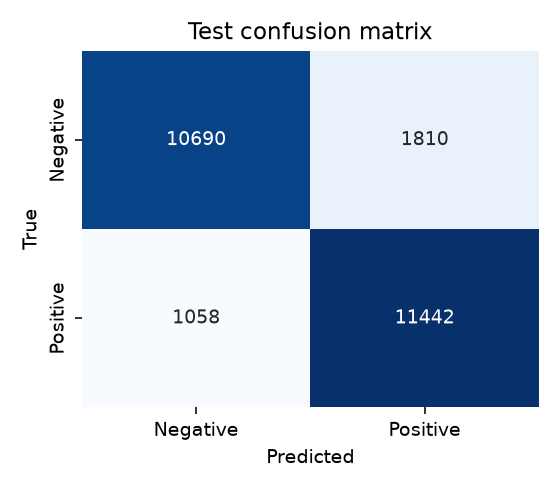

In [5]:
test_metrics = evaluate_selected(STUDY_DIR)
display(test_metrics)
display(pd.read_csv(STUDY_DIR / "final_comparison.csv"))
display(Image(filename=str(STUDY_DIR / "final" / "confusion_matrix.png")))

## 6. Report and export

The report identifies observed validation improvements and regressions for every completed ablation. It includes training cost and separates research motivation from this repository's findings. No architecture or starting hyperparameter is assumed optimal.

This single-seed, fixed-budget study does not measure all interactions. Test results must not trigger new configuration trials in this study. Download artifacts before a Colab session ends.

In [6]:
report_study(STUDY_DIR)
display(Markdown((STUDY_DIR / "report.md").read_text(encoding="utf-8")))
print("Full experiment status:", "Completed" if MODE == "full" else "Not run in this smoke execution")

# LSTM optimization study

Full 20k/5k validation study, seed 42.

| experiment_id | status | val_accuracy | val_f1 | val_loss | training_seconds | best_epoch | delta_accuracy_pp |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 01_original_control | complete | 0.8452 | 0.8514 | 0.3960 | 53.7118 | 5 | -3.4200 |
| 02_anchor | complete | 0.8794 | 0.8758 | 0.2795 | 329.1722 | 15 | 0.0000 |
| 03_vocab_20000 | complete | 0.8768 | 0.8820 | 0.2915 | 327.5208 | 14 | -0.2600 |
| 04_length_300 | complete | 0.8714 | 0.8687 | 0.3035 | 253.6196 | 12 | -0.8000 |
| 05_length_500 | complete | 0.8840 | 0.8850 | 0.2819 | 382.5686 | 15 | 0.4600 |
| 06_head_tail | complete | 0.8804 | 0.8814 | 0.2800 | 323.3310 | 15 | 0.1000 |
| 07_unidirectional | complete | 0.8666 | 0.8679 | 0.3211 | 167.9347 | 8 | -1.2800 |
| 08_final_pooling | complete | 0.8658 | 0.8596 | 0.3219 | 213.5752 | 14 | -1.3600 |
| 09_max_pooling | complete | 0.8842 | 0.8839 | 0.2791 | 316.5378 | 14 | 0.4800 |
| 10_no_embedding_dropout | complete | 0.8784 | 0.8766 | 0.3134 | 323.5270 | 14 | -0.1000 |
| 11_classifier_dropout_03 | complete | 0.8792 | 0.8793 | 0.2902 | 323.3777 | 14 | -0.0200 |
| 12_word_dropout | complete | 0.8862 | 0.8890 | 0.2825 | 324.8152 | 15 | 0.6800 |
| 13_no_weight_decay | complete | 0.8666 | 0.8706 | 0.3464 | 216.6483 | 6 | -1.2800 |
| 14_exponential_scheduler | complete | 0.8682 | 0.8685 | 0.3100 | 320.3695 | 15 | -1.1200 |
| 15_learning_rate_001 | complete | 0.8802 | 0.8822 | 0.2820 | 213.6078 | 6 | 0.0800 |
| 16_short_budget | complete | 0.8578 | 0.8575 | 0.3325 | 170.7553 | 7 | -2.1600 |

Frozen winner: **12_word_dropout**. Ranking: validation accuracy descending, F1 descending, loss ascending, experiment ID ascending. Checkpoints are restored by validation loss; no test metric selected configurations.

## Observed ablations

- Vocabulary 20000: reduced validation accuracy relative to the anchor (-0.26 percentage points); F1 change +0.0062, loss change +0.0120; training 327.52s.
- Sequence length 300: reduced validation accuracy relative to the anchor (-0.80 percentage points); F1 change -0.0070, loss change +0.0240; training 253.62s.
- Sequence length 500: improved validation accuracy relative to the anchor (+0.46 percentage points); F1 change +0.0092, loss change +0.0024; training 382.57s.
- Head-tail truncation: improved validation accuracy relative to the anchor (+0.10 percentage points); F1 change +0.0056, loss change +0.0005; training 323.33s.
- Unidirectional recurrence: reduced validation accuracy relative to the anchor (-1.28 percentage points); F1 change -0.0079, loss change +0.0416; training 167.93s.
- Final-state pooling: reduced validation accuracy relative to the anchor (-1.36 percentage points); F1 change -0.0162, loss change +0.0424; training 213.58s.
- Masked max pooling: improved validation accuracy relative to the anchor (+0.48 percentage points); F1 change +0.0081, loss change -0.0004; training 316.54s.
- Embedding dropout disabled: reduced validation accuracy relative to the anchor (-0.10 percentage points); F1 change +0.0008, loss change +0.0339; training 323.53s.
- Classifier dropout 0.3: reduced validation accuracy relative to the anchor (-0.02 percentage points); F1 change +0.0035, loss change +0.0107; training 323.38s.
- Word dropout 0.1: improved validation accuracy relative to the anchor (+0.68 percentage points); F1 change +0.0132, loss change +0.0030; training 324.82s.
- Weight decay disabled: reduced validation accuracy relative to the anchor (-1.28 percentage points); F1 change -0.0052, loss change +0.0669; training 216.65s.
- Exponential LR decay gamma 0.95: reduced validation accuracy relative to the anchor (-1.12 percentage points); F1 change -0.0073, loss change +0.0305; training 320.37s.
- Learning rate 0.001: improved validation accuracy relative to the anchor (+0.08 percentage points); F1 change +0.0065, loss change +0.0025; training 213.61s.
- Maximum 8 epochs and patience 2: reduced validation accuracy relative to the anchor (-2.16 percentage points); F1 change -0.0183, loss change +0.0531; training 170.76s.

The original control versus anchor changes a bundle of settings. The short-budget experiment changes both epochs and patience. Other ablations change one listed setting. Single-seed differences are descriptive, not significance tests; feature interactions are not measured.

Total completed candidate training time: 4261.07s, excluding preprocessing, selection and final test.

## Final test

| model | status | accuracy | f1 | macro_f1 | training_seconds |
| --- | --- | --- | --- | --- | --- |
| logreg | historical benchmark | 0.9023 | 0.9023 | 0.9023 | 3.4866 |
| svm | historical benchmark | 0.9009 | 0.9006 | 0.9009 | 3.5356 |
| rnn | historical benchmark | 0.7526 | 0.7420 | 0.7521 | 78.0468 |
| lstm | historical benchmark | 0.8403 | 0.8460 | 0.8401 | 87.9016 |
| selected:12_word_dropout | full | 0.8853 | 0.8886 | 0.8852 | 324.8152 |

Historical results are unchanged, on the same split. They were read for reporting only after selection and final evaluation. Timings compare different architectures/devices and exclude preprocessing.

## Research basis and departures

[Hameed & Garcia-Zapirain (2020)](https://doi.org/10.1109/ACCESS.2020.2988550) motivates BiLSTM mean/max pooling, regularization and evaluating 400 tokens; its GloVe embeddings and cross-validation differ from this study. [Sachan et al. (arXiv:2009.04007)](https://arxiv.org/abs/2009.04007) motivates max pooling, embedding/word dropout, vocabulary ablations and learning-rate decay; its pretrained embeddings and semi-supervised objectives are excluded here. The [Keras example](https://keras.io/examples/nlp/bidirectional_lstm_imdb/) illustrates bidirectional recurrence but uses a different validation protocol. Here embeddings are randomly initialized and trained only on 20k labeled training reviews; the official test split is never used for tuning. Head-tail truncation, exact dropout values, decay gamma and other starting hyperparameters are local hypotheses, not established optima. Published results are not directly reproducible under this repository's split or protocol.


Full experiment status: Completed


In [7]:
import shutil
archive_path = shutil.make_archive(str(STUDY_DIR), "zip", root_dir=STUDY_DIR.parent, base_dir=STUDY_DIR.name)
print("Artifacts:", archive_path)
if IN_COLAB:
    from google.colab import files
    files.download(archive_path)

Artifacts: C:\Users\letie\Documents\Journals\NLP\outputs\lstm_optimization\full-20261027T181317-42224b37.zip
